<a href="https://colab.research.google.com/github/adalisiwar/Neurotrace/blob/main/NeuroTrace_MobileNetV3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuroTrace — MobileNetV3-Large sur Brain Tumor MRI Dataset


**Ce que fait ce notebook**
1. Trouve / télécharge le dataset (Masoud Nickparvar, 4 classes : glioma, meningioma, notumor, pituitary).
2. Supprime les **doublons exacts** (dans Training, et entre Training et Testing) pour éviter la fuite de données.
3. Prétraitement (recadrage du cerveau, 224×224, CLAHE) + augmentation légère (train seulement).
4. Entraînement en **2 phases** (tête seule, puis fine-tuning complet), AdamW, label smoothing, AMP, arrêt anticipé sur le **F1 macro de validation**.
5. Évaluation sur le **Test (une seule fois)** : Accuracy, Precision, Recall, F1, matrice de confusion, ROC-AUC, **calibration** (ECE + temperature scaling), vitesse, taille.
6. Grad-CAM, erreurs, et export (`metrics.json`, `model_card.json`, poids, prédictions, zip).

**Modèle** : MobileNetV3-Large (≈5 M paramètres) : rapide, idéal pour la démonstration NeuroTrace.

In [ ]:
import importlib, subprocess, sys
for pkg, mod in [("scikit-learn", "sklearn"), ("opencv-python-headless", "cv2"), ("kagglehub", "kagglehub"), ("tqdm", "tqdm"), ("pandas", "pandas")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("OK")

OK


In [ ]:
# 2) Configuration — c'est la seule cellule à modifier si besoin
MODEL_NAME = "mobilenet_v3_large"          # "mobilenet_v3_large"
PRETRAINED = True                    # poids ImageNet (recommandé)
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_FROZEN = 2                    # phase 1 : seule la tête est entraînée
EPOCHS_FINETUNE = 28                 # phase 2 : tout le réseau (arrêt anticipé possible)
PATIENCE = 6                         # arrêt si le F1 macro de validation ne progresse plus
LR_HEAD = 1e-3
LR_BACKBONE = 3e-4
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
DROPOUT = 0.3
USE_CLAHE = True
USE_CLASS_WEIGHTS = True
VAL_FRACTION = 0.15
MODEL_VERSION = f"neurotrace-{MODEL_NAME}-v1.0"
OUT_DIR = f"outputs_{MODEL_NAME}"

In [ ]:
import os, time, json, copy, hashlib, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_auc_score)
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
torch.backends.cudnn.benchmark = True
os.makedirs(OUT_DIR, exist_ok=True)
print("torch", torch.__version__, "| device:", device)
if device.type == "cpu":
    print("ATTENTION : pas de GPU détecté. L'entraînement sera très lent. Active un GPU (Kaggle: Accelerator, Colab: type d'exécution).")

torch 2.11.0+cu130 | device: cuda


## 3) Localiser le dataset
Cherche un dossier contenant `Training` et `Testing`. Sur Kaggle il est dans `/kaggle/input/...`. Sinon, téléchargement automatique avec `kagglehub`.
Si le téléchargement demande une authentification : sur Kaggle.com → *Settings → API → Create New Token*, puis dans Colab définir `KAGGLE_USERNAME` et `KAGGLE_KEY` (variables d'environnement) et relancer la cellule.

In [ ]:
def search_root(base):
    if not os.path.isdir(base):
        return None
    for dp, dn, _ in os.walk(base):
        low = {d.lower(): d for d in dn}
        if "training" in low and "testing" in low:
            return dp
    return None

DATA_ROOT = None
for base in ["/kaggle/input", "./data", "/content", "."]:
    DATA_ROOT = search_root(base)
    if DATA_ROOT:
        break
if DATA_ROOT is None:
    import kagglehub
    p = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
    DATA_ROOT = search_root(p)
assert DATA_ROOT, "Dataset introuvable : ajoute-le au notebook (Kaggle) ou vérifie l'authentification Kaggle."
print("Dataset :", DATA_ROOT)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset : /kaggle/input/brain-tumor-mri-dataset


## 4) Liste des images, doublons et splits
- Les **doublons exacts** (même contenu) sont retirés du Training ; ceux déjà présents dans le Training sont retirés du Testing.
- Une image présente avec deux labels différents est retirée.
- La validation (15 %) est tirée du Training (stratifiée). **Le Test n'est utilisé qu'à la fin.**

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


hash:   0%|          | 0/7200 [00:00<?, ?it/s]

Images listées : 7200 | contradictoires retirées : 0 | doublons train retirés : 171 | test dupliqué/dans train retiré : 16
class  glioma  meningioma  notumor  pituitary
split                                        
test      386         398      400        400
train    1190        1178     1089       1157
val       210         208      192        205


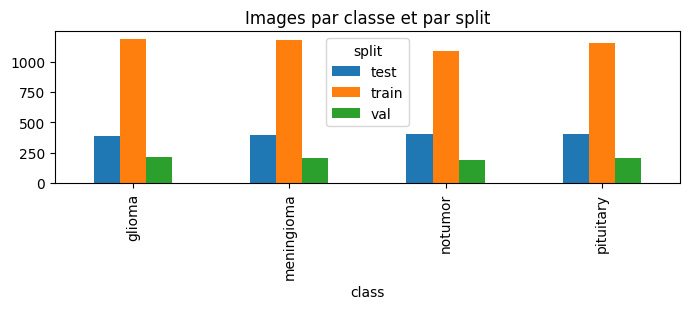

In [ ]:
EXT = {".jpg", ".jpeg", ".png", ".bmp"}
root = Path(DATA_ROOT)
sub = {d.name.lower(): d for d in root.iterdir() if d.is_dir()}
CLASS_NAMES = sorted([d.name for d in sub["training"].iterdir() if d.is_dir()])
print("Classes :", CLASS_NAMES)
assert len(CLASS_NAMES) >= 2
label_of = {n: i for i, n in enumerate(CLASS_NAMES)}

rows = []
for split in ["training", "testing"]:
    for cname in CLASS_NAMES:
        # le nom du dossier de classe peut varier de casse entre Training et Testing
        cdirs = [d for d in sub[split].iterdir() if d.is_dir() and d.name.lower() == cname.lower()]
        for cd in cdirs:
            for f in sorted(cd.rglob("*")):
                if f.suffix.lower() in EXT:
                    rows.append((str(f), cname, "train" if split == "training" else "test"))
df = pd.DataFrame(rows, columns=["path", "class", "orig_split"])

def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

df["md5"] = [md5(p) for p in tqdm(df["path"], desc="hash")]
n0 = len(df)

# labels contradictoires pour un même contenu
conf = df.groupby("md5")["class"].nunique()
bad = conf[conf > 1].index
df = df[~df["md5"].isin(bad)]
tr = df[df.orig_split == "train"].drop_duplicates("md5")
te = df[df.orig_split == "test"].drop_duplicates("md5")
te = te[~te["md5"].isin(set(tr["md5"]))]
print(f"Images listées : {n0} | contradictoires retirées : {n0 - len(df)} | "
      f"doublons train retirés : {(df.orig_split=='train').sum() - len(tr)} | "
      f"test dupliqué/dans train retiré : {(df.orig_split=='test').sum() - len(te)}")

tr_df, va_df = train_test_split(tr, test_size=VAL_FRACTION, stratify=tr["class"], random_state=SEED)
tr_df, va_df, te_df = tr_df.copy(), va_df.copy(), te.copy()
tr_df["split"], va_df["split"], te_df["split"] = "train", "val", "test"
splits = pd.concat([tr_df, va_df, te_df])[["path", "class", "split", "md5"]]
splits.to_csv(f"{OUT_DIR}/splits.csv", index=False)   # même fichier = comparaison équitable entre modèles (SEED identique)

counts = splits.groupby(["split", "class"]).size().unstack(fill_value=0)
print(counts)
counts.T.plot(kind="bar", figsize=(7, 3.2), title="Images par classe et par split"); plt.tight_layout(); plt.show()

## 5) Prétraitement (identique entraînement / inference)
Recadrage du cerveau → redimensionnement → CLAHE. Les images prétraitées (niveaux de gris, 224×224) sont mises en cache en mémoire pour accélérer l'entraînement.

prétraitement:   0%|          | 0/4614 [00:00<?, ?it/s]

prétraitement:   0%|          | 0/815 [00:00<?, ?it/s]

prétraitement:   0%|          | 0/1584 [00:00<?, ?it/s]

4614 815 1584 images prêtes


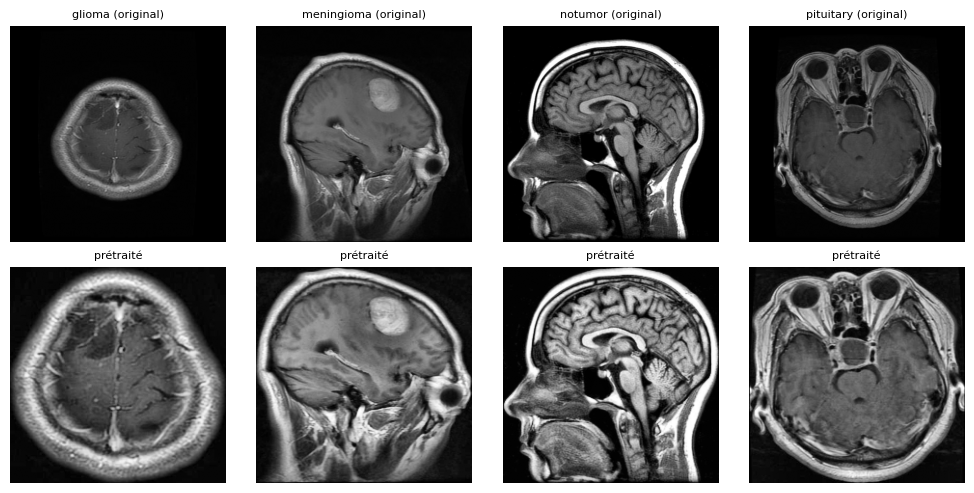

In [ ]:
def preprocess_gray(path, size=IMG_SIZE, use_clahe=USE_CLAHE):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None or img.size == 0:
        return None
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    _, th = cv2.threshold(blur, 20, 255, cv2.THRESH_BINARY)
    th = cv2.dilate(cv2.erode(th, None, iterations=2), None, iterations=2)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        if w * h > 0.2 * img.shape[0] * img.shape[1]:      # sécurité : on ne recadre pas si le masque est aberrant
            img = img[y:y + h, x:x + w]
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    if use_clahe:
        img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)
    return img

def load_split(d):
    arrs, labs, paths = [], [], []
    for p, c in tqdm(zip(d["path"], d["class"]), total=len(d), desc="prétraitement"):
        a = preprocess_gray(p)
        if a is None:
            continue                                      # image illisible : ignorée
        arrs.append(a); labs.append(label_of[c]); paths.append(p)
    return arrs, np.array(labs), paths

Xtr, ytr, ptr = load_split(tr_df)
Xva, yva, pva = load_split(va_df)
Xte, yte, pte = load_split(te_df)
print(len(Xtr), len(Xva), len(Xte), "images prêtes")

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for j, cname in enumerate(CLASS_NAMES[:4]):
    i = int(np.where(ytr == label_of[cname])[0][0])
    ax[0, j].imshow(cv2.imread(ptr[i], cv2.IMREAD_GRAYSCALE), cmap="gray"); ax[0, j].set_title(f"{cname} (original)", fontsize=8)
    ax[1, j].imshow(Xtr[i], cmap="gray"); ax[1, j].set_title("prétraité", fontsize=8)
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class MRIDataset(Dataset):
    def __init__(self, arrays, labels, train):
        self.a, self.y, self.tf = arrays, labels, (train_tf if train else eval_tf)
    def __len__(self): return len(self.a)
    def __getitem__(self, i):
        img = Image.fromarray(self.a[i]).convert("RGB")
        return self.tf(img), int(self.y[i])

NW = min(2, os.cpu_count() or 1)
def make_loader(X, y, train):
    return DataLoader(MRIDataset(X, y, train), batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      num_workers=NW, pin_memory=device.type == "cuda", persistent_workers=NW > 0)
train_dl, val_dl, test_dl = make_loader(Xtr, ytr, True), make_loader(Xva, yva, False), make_loader(Xte, yte, False)

## 6) Modèle

In [ ]:
def build_model(name, n_classes, pretrained, dropout):
    try:
        if name == "mobilenet_v3_large":
            w = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
            m = models.mobilenet_v3_large(weights=w)
            m.classifier[2] = nn.Dropout(dropout)
            m.classifier[3] = nn.Linear(m.classifier[3].in_features, n_classes)
            head, cam_layer = m.classifier, m.features[-1]
        elif name == "densenet121":
            w = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
            m = models.densenet121(weights=w)
            m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier.in_features, n_classes))
            head, cam_layer = m.classifier, m.features.denseblock4
        else:
            raise ValueError(name)
    except Exception as e:
        raise RuntimeError("Impossible de charger les poids ImageNet. Sur Kaggle, active Internet (Settings > Internet On). "
                           f"Détail : {e}")
    for mod in m.modules():                    # nécessaire pour un Grad-CAM fiable
        if hasattr(mod, "inplace"):
            mod.inplace = False
    return m, list(m.features.parameters()), list(head.parameters()), cam_layer

model, backbone_params, head_params, cam_layer = build_model(MODEL_NAME, len(CLASS_NAMES), PRETRAINED, DROPOUT)
model = model.to(device)
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} : {N_PARAMS/1e6:.2f} M paramètres")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 165MB/s]


mobilenet_v3_large : 4.21 M paramètres


## 7) Entraînement (2 phases)
- **Phase 1** : le backbone est gelé, seule la tête apprend (stabilise la nouvelle couche de sortie).
- **Phase 2** : fine-tuning complet, warm-up 1 époque puis décroissance cosinus, clipping du gradient.
- Sélection du meilleur modèle sur le **F1 macro de validation** (jamais sur le Test).

poids de classes : {'glioma': np.float32(0.97), 'meningioma': np.float32(0.98), 'notumor': np.float32(1.06), 'pituitary': np.float32(1.0)}


/tmp/ipykernel_1681/2084512090.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[tête] epoch 01 | train_loss 0.6995 | val_loss 0.3477 | val_acc 0.9006 | val_F1 0.9023  *
[tête] epoch 02 | train_loss 0.5855 | val_loss 0.3422 | val_acc 0.8969 | val_F1 0.8989
[fine-tuning] epoch 03 | train_loss 0.6107 | val_loss 0.4947 | val_acc 0.8368 | val_F1 0.8245
[fine-tuning] epoch 04 | train_loss 0.4950 | val_loss 0.3274 | val_acc 0.9129 | val_F1 0.9102  *
[fine-tuning] epoch 05 | train_loss 0.4341 | val_loss 0.2057 | val_acc 0.9742 | val_F1 0.9745  *
[fine-tuning] epoch 06 | train_loss 0.3913 | val_loss 0.1254 | val_acc 0.9877 | val_F1 0.9879  *
[fine-tuning] epoch 07 | train_loss 0.3848 | val_loss 0.1030 | val_acc 0.9939 | val_F1 0.9939  *
[fine-tuning] epoch 08 | train_loss 0.3747 | val_loss 0.0941 | val_acc 0.9926 | val_F1 0.9927
[fine-tuning] epoch 09 | train_loss 0.3683 | val_loss 0.0994 | val_acc 0.9939 | val_F1 0.9938
[fine-tuning] epoch 10 | train_loss 0.3631 | val_loss 0.1040 | val_acc 0.9926 | val_F1 0.9927
[fine-tuning] epoch 11 | train_loss 0.3665 | val_loss 0.093

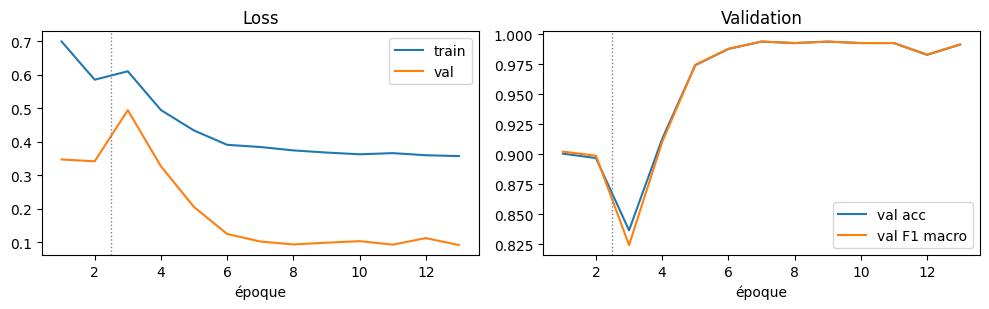

In [ ]:
cw = None
if USE_CLASS_WEIGHTS:
    cnt = np.bincount(ytr, minlength=len(CLASS_NAMES)).astype(float)
    cw = torch.tensor(cnt.sum() / (len(cnt) * cnt), dtype=torch.float32, device=device)
    print("poids de classes :", dict(zip(CLASS_NAMES, cw.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def macro_f1(y, p):
    return precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]

@torch.no_grad()
def predict_logits(m, loader, tta=False):
    m.eval(); out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            lg = m(x).float()
            if tta:
                lg = (lg + m(torch.flip(x, dims=[3])).float()) / 2
        out.append(lg.cpu())
    return torch.cat(out).numpy()

def train_one_epoch(m, opt, freeze_backbone):
    m.train()
    if freeze_backbone:
        m.features.eval()                    # garde les statistiques BN du backbone figées
    tot, n = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            loss = criterion(m(x), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        tot += loss.item() * len(y); n += len(y)
    return tot / n

history, best = [], {"f1": -1, "loss": 1e9, "state": None, "epoch": -1}
bad_epochs = 0

def validate(ep, phase, train_loss):
    global bad_epochs
    lg = predict_logits(model, val_dl)
    p = lg.argmax(1)
    vloss = float(F.cross_entropy(torch.tensor(lg), torch.tensor(yva)))
    f1, acc = macro_f1(yva, p), accuracy_score(yva, p)
    history.append(dict(epoch=ep, phase=phase, train_loss=train_loss, val_loss=vloss, val_acc=acc, val_f1=f1))
    improved = f1 > best["f1"] + 1e-4 or (abs(f1 - best["f1"]) <= 1e-4 and vloss < best["loss"])
    if improved:
        best.update(f1=f1, loss=vloss, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        torch.save(best["state"], f"{OUT_DIR}/best.pt")
        bad_epochs = 0
    else:
        bad_epochs += 1
    print(f"[{phase}] epoch {ep:02d} | train_loss {train_loss:.4f} | val_loss {vloss:.4f} | val_acc {acc:.4f} | val_F1 {f1:.4f}"
          + ("  *" if improved else ""))

t0 = time.time()
# ---- Phase 1 : tête seule
for p in backbone_params: p.requires_grad = False
opt = torch.optim.AdamW(head_params, lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
for ep in range(1, EPOCHS_FROZEN + 1):
    validate(ep, "tête", train_one_epoch(model, opt, True))

# ---- Phase 2 : fine-tuning complet
for p in backbone_params: p.requires_grad = True
opt = torch.optim.AdamW([{"params": backbone_params, "lr": LR_BACKBONE},
                         {"params": head_params, "lr": LR_BACKBONE * 3}], weight_decay=WEIGHT_DECAY)
base_lrs = [g["lr"] for g in opt.param_groups]
bad_epochs = 0
for k in range(EPOCHS_FINETUNE):
    f = 0.3 if k == 0 else 0.5 * (1 + np.cos(np.pi * (k - 1) / max(1, EPOCHS_FINETUNE - 1)))   # warm-up puis cosinus
    for g, b in zip(opt.param_groups, base_lrs):
        g["lr"] = b * max(f, 0.02)
    validate(EPOCHS_FROZEN + k + 1, "fine-tuning", train_one_epoch(model, opt, False))
    if bad_epochs >= PATIENCE:
        print(f"Arrêt anticipé : pas d'amélioration depuis {PATIENCE} époques.")
        break
TRAIN_MIN = (time.time() - t0) / 60
print(f"\nMeilleure époque : {best['epoch']} (val F1 {best['f1']:.4f}) | durée {TRAIN_MIN:.1f} min")
model.load_state_dict(best["state"]); model.to(device)

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc, label="val acc"); ax[1].plot(h.epoch, h.val_f1, label="val F1 macro"); ax[1].set_title("Validation"); ax[1].legend()
for a in ax: a.axvline(EPOCHS_FROZEN + 0.5, color="gray", ls=":", lw=1); a.set_xlabel("époque")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

## 8) Évaluation finale
Logits avec TTA (image + miroir horizontal). **Temperature scaling** appris sur la validation uniquement, puis appliqué au Test : il améliore la fiabilité de la confiance (utile pour les règles Accepté / Révision requise / Rejeté de NeuroTrace) sans changer les classes prédites.

In [ ]:
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z.astype(np.float64)); return e / e.sum(1, keepdims=True)

def fit_temperature(logits, y):
    lg, yy = torch.tensor(logits, dtype=torch.float32), torch.tensor(y)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(lg / log_t.exp(), yy); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.exp().item())

def ece_score(probs, y, n_bins=15):
    conf, correct = probs.max(1), (probs.argmax(1) == y).astype(float)
    edges, e = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def full_metrics(y, probs):
    pred = probs.argmax(1)
    pm, rm, fm, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    try:
        auc = float(roc_auc_score(y, probs, multi_class="ovr", average="macro", labels=list(range(probs.shape[1]))))
    except ValueError:
        auc = float("nan")
    rep = classification_report(y, pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    return dict(accuracy=float(accuracy_score(y, pred)), precision_macro=float(pm), recall_macro=float(rm), f1_macro=float(fm),
                f1_weighted=float(fw), roc_auc_ovr=auc, ece=ece_score(probs, y),
                nll=float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1)).mean()),
                per_class={c: dict(precision=rep[c]["precision"], recall=rep[c]["recall"], f1=rep[c]["f1-score"], support=int(rep[c]["support"]))
                           for c in CLASS_NAMES})

lg_val = predict_logits(model, val_dl, tta=True)
lg_test = predict_logits(model, test_dl, tta=True)
TEMP = fit_temperature(lg_val, yva)
print(f"Température apprise sur la validation : T = {TEMP:.3f}")

P_val, P_test_raw, P_test = softmax(lg_val / TEMP), softmax(lg_test), softmax(lg_test / TEMP)
M_val = full_metrics(yva, P_val)
M_test_raw = full_metrics(yte, P_test_raw)
M_test = full_metrics(yte, P_test)

tab = pd.DataFrame({"Validation": M_val, "Test (sans T)": M_test_raw, "Test (avec T)": M_test}).drop(index="per_class")
print(tab.astype(float).round(4).to_string())
print("\nRapport par classe (Test) :")
print(pd.DataFrame(M_test["per_class"]).T.round(4).to_string())

Température apprise sur la validation : T = 0.377
                 Validation  Test (sans T)  Test (avec T)
accuracy             0.9963         0.9609         0.9609
precision_macro      0.9964         0.9630         0.9630
recall_macro         0.9963         0.9600         0.9600
f1_macro             0.9963         0.9598         0.9598
f1_weighted          0.9963         0.9602         0.9602
roc_auc_ovr          0.9999         0.9892         0.9899
ece                  0.0061         0.0582         0.0327
nll                  0.0183         0.1889         0.2406

Rapport par classe (Test) :
            precision  recall      f1  support
glioma         0.9910  0.8575  0.9194    386.0
meningioma     0.9140  0.9874  0.9493    398.0
notumor        0.9547  1.0000  0.9768    400.0
pituitary      0.9925  0.9950  0.9938    400.0


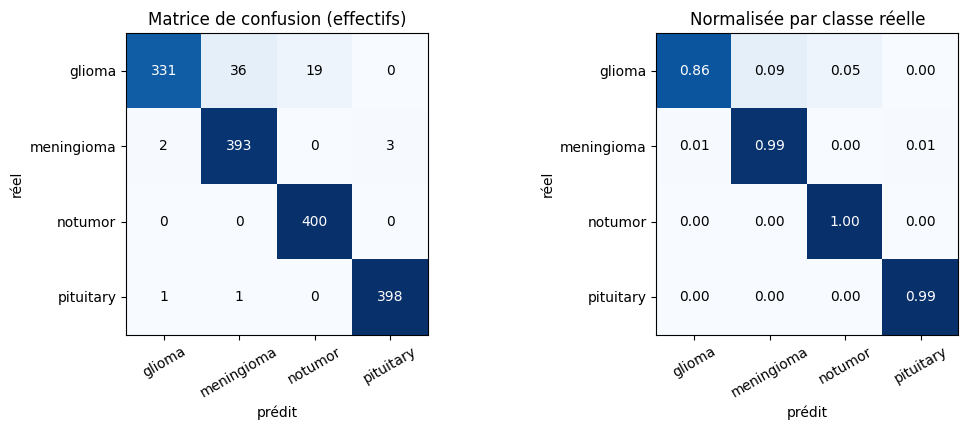

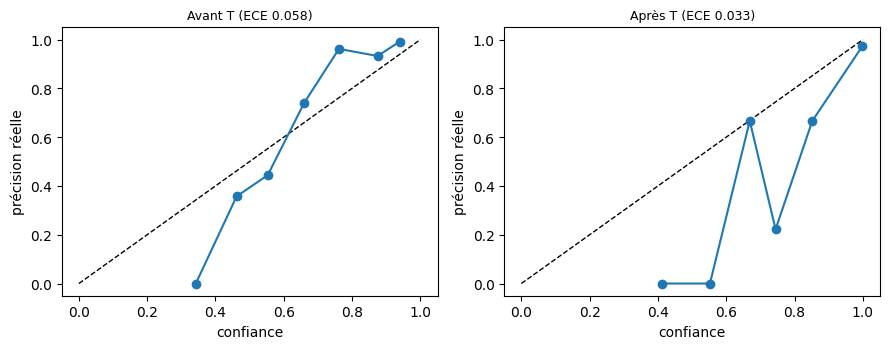

Params 4.21 M | poids 17.0 MB | inference CPU 39.2 ms/image


In [ ]:
pred_test = P_test.argmax(1)
cm = confusion_matrix(yte, pred_test, labels=list(range(len(CLASS_NAMES))))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, mat, ttl, fmt in [(ax[0], cm, "Matrice de confusion (effectifs)", "d"), (ax[1], cmn, "Normalisée par classe réelle", ".2f")]:
    im = a.imshow(mat, cmap="Blues"); a.set_title(ttl)
    a.set_xticks(range(len(CLASS_NAMES))); a.set_yticks(range(len(CLASS_NAMES)))
    a.set_xticklabels(CLASS_NAMES, rotation=30); a.set_yticklabels(CLASS_NAMES)
    a.set_xlabel("prédit"); a.set_ylabel("réel")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            a.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_test.png", dpi=150); plt.show()

def reliability(ax, probs, y, title, n_bins=10):
    conf, correct = probs.max(1), (probs.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 0:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(xs, ys, "o-"); ax.set_title(title, fontsize=9)
    ax.set_xlabel("confiance"); ax.set_ylabel("précision réelle")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
reliability(ax[0], P_test_raw, yte, f"Avant T (ECE {M_test_raw['ece']:.3f})")
reliability(ax[1], P_test, yte, f"Après T (ECE {M_test['ece']:.3f})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/reliability.png", dpi=150); plt.show()

# Taille et vitesse
SIZE_MB = os.path.getsize(f"{OUT_DIR}/best.pt") / 1e6
m_cpu = copy.deepcopy(model).cpu().eval()
xx = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    for _ in range(5): m_cpu(xx)
    t = time.perf_counter()
    for _ in range(30): m_cpu(xx)
CPU_MS = (time.perf_counter() - t) / 30 * 1000
del m_cpu
print(f"Params {N_PARAMS/1e6:.2f} M | poids {SIZE_MB:.1f} MB | inference CPU {CPU_MS:.1f} ms/image")

## 9) Analyse des erreurs et Grad-CAM

62 erreurs sur 1584 images de test


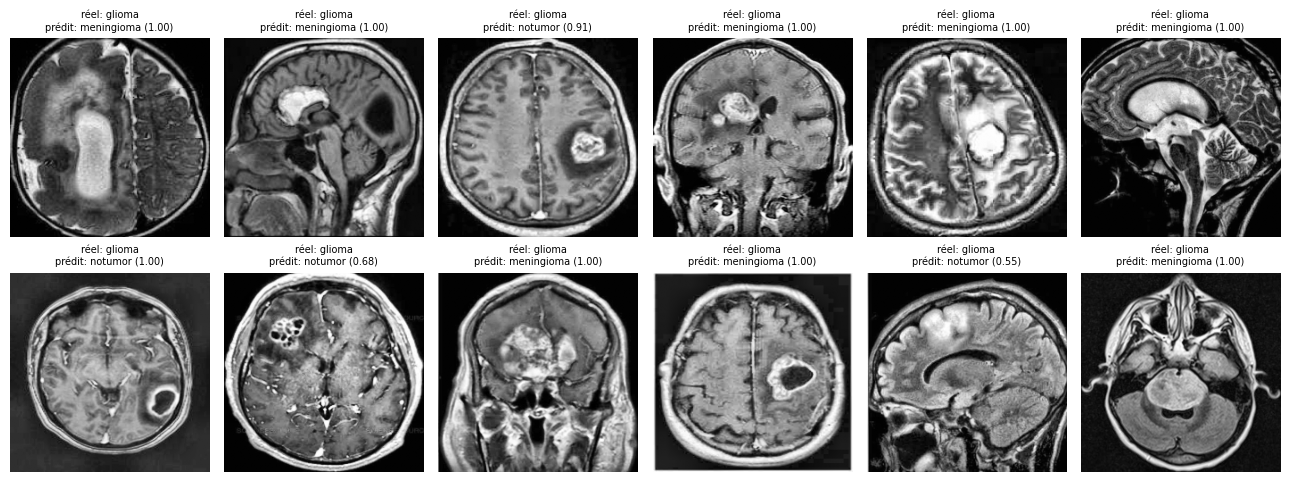

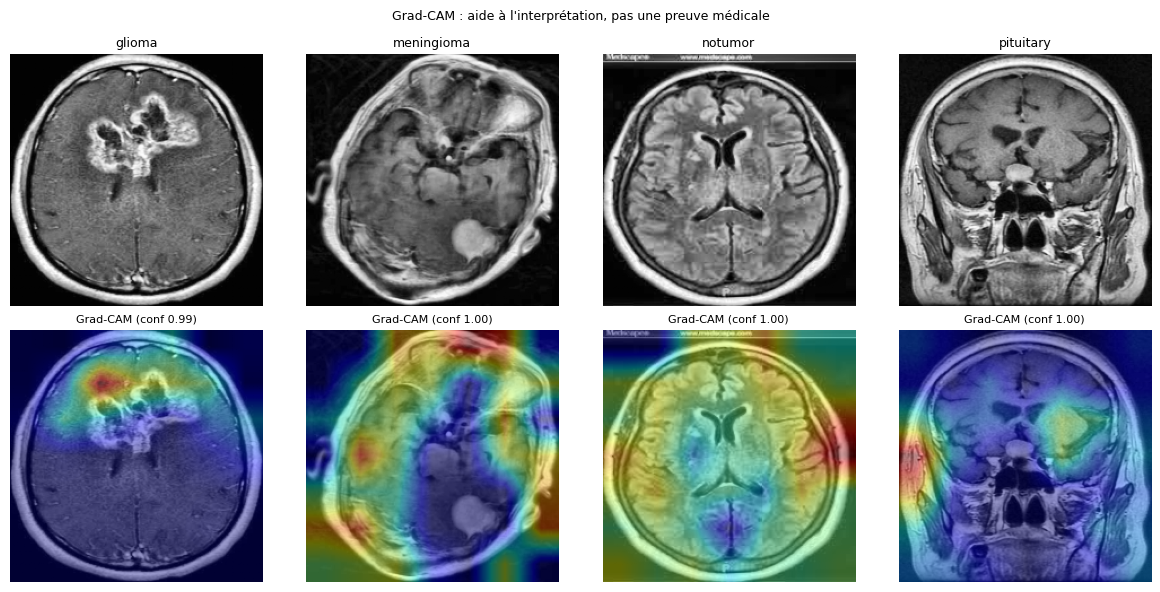

In [ ]:
# Images mal classées (Test)
wrong = np.where(pred_test != yte)[0]
print(f"{len(wrong)} erreurs sur {len(yte)} images de test")
if len(wrong):
    sel = wrong[:12]
    fig, ax = plt.subplots(2, 6, figsize=(13, 5))
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), sel):
        a.imshow(Xte[i], cmap="gray")
        a.set_title(f"réel: {CLASS_NAMES[yte[i]]}\nprédit: {CLASS_NAMES[pred_test[i]]} ({P_test[i].max():.2f})", fontsize=7)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/errors.png", dpi=150); plt.show()

class GradCAM:
    def __init__(self, m, layer):
        self.m, self.acts, self.grads = m, None, None
        self.h = layer.register_forward_hook(self._fwd)
    def _fwd(self, mod, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, cls=None):
        self.m.eval()
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            out = self.m(x)
            cls = out.argmax(1) if cls is None else cls
            self.m.zero_grad(set_to_none=True)
            out[torch.arange(len(x), device=out.device), cls].sum().backward()
            w = self.grads.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((w * self.acts).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        return ((cam - mn) / (mx - mn + 1e-8)).cpu().numpy()
    def close(self): self.h.remove()

gc = GradCAM(model, cam_layer)
fig, ax = plt.subplots(2, len(CLASS_NAMES), figsize=(3 * len(CLASS_NAMES), 6))
for j, cname in enumerate(CLASS_NAMES):
    ok = np.where((yte == j) & (pred_test == j))[0]
    if len(ok) == 0:
        continue
    i = int(ok[0])
    x = eval_tf(Image.fromarray(Xte[i]).convert("RGB"))[None].to(device)
    cam = gc(x)[0]
    ax[0, j].imshow(Xte[i], cmap="gray"); ax[0, j].set_title(cname, fontsize=9)
    ax[1, j].imshow(Xte[i], cmap="gray"); ax[1, j].imshow(cam, cmap="jet", alpha=0.4)
    ax[1, j].set_title(f"Grad-CAM (conf {P_test[i].max():.2f})", fontsize=8)
    ax[0, j].axis("off"); ax[1, j].axis("off")
gc.close()
plt.suptitle("Grad-CAM : aide à l'interprétation, pas une preuve médicale", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gradcam.png", dpi=150); plt.show()

## 10) Export pour NeuroTrace
Fichiers produits dans le dossier `outputs_<modèle>/` : `best.pt`, `metrics.json`, `model_card.json`, `test_predictions.csv`, `splits.csv`, les figures PNG, et un zip.
Les deux notebooks écrivent `metrics.json` avec **le même format** : utilise-les pour remplir le tableau de décision du guide.

In [ ]:
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

tumour_idx = [i for i, c in enumerate(CLASS_NAMES) if c.lower() not in ("notumor", "no_tumor", "no tumor", "normal")]
tumour_recall = float(np.mean([M_test["per_class"][CLASS_NAMES[i]]["recall"] for i in tumour_idx]))

cfg = {k: globals()[k] for k in ["MODEL_NAME", "PRETRAINED", "SEED", "IMG_SIZE", "BATCH_SIZE", "EPOCHS_FROZEN", "EPOCHS_FINETUNE", "PATIENCE",
                                 "LR_HEAD", "LR_BACKBONE", "WEIGHT_DECAY", "LABEL_SMOOTHING", "DROPOUT", "USE_CLAHE", "USE_CLASS_WEIGHTS", "VAL_FRACTION"]}
metrics = dict(model=MODEL_NAME, version=MODEL_VERSION, classes=CLASS_NAMES, best_epoch=int(best["epoch"]), train_minutes=round(TRAIN_MIN, 1),
               n_train=int(len(ytr)), n_val=int(len(yva)), n_test=int(len(yte)), temperature=TEMP,
               validation=M_val, test_raw=M_test_raw, test_calibrated=M_test, tumour_recall_macro=tumour_recall,
               params_millions=round(N_PARAMS / 1e6, 2), weights_mb=round(SIZE_MB, 1), cpu_ms_per_image=round(CPU_MS, 1), config=cfg)
json.dump(metrics, open(f"{OUT_DIR}/metrics.json", "w"), indent=2)

card = dict(model_name=MODEL_NAME, version=MODEL_VERSION, classes=CLASS_NAMES, input_size=IMG_SIZE,
            preprocessing=dict(crop="brain bounding box (threshold 20)", resize=IMG_SIZE, clahe=USE_CLAHE, normalize_mean=MEAN, normalize_std=STD),
            temperature=TEMP, seed=SEED, weights_file="best.pt", weights_sha256=sha256_file(f"{OUT_DIR}/best.pt"),
            test_accuracy=M_test["accuracy"], test_f1_macro=M_test["f1_macro"], test_ece=M_test["ece"],
            disclaimer="Prototype pédagogique, non destiné au diagnostic clinique.")
json.dump(card, open(f"{OUT_DIR}/model_card.json", "w"), indent=2)

pt = pd.DataFrame(P_test, columns=[f"p_{c}" for c in CLASS_NAMES])
pt.insert(0, "path", pte); pt.insert(1, "true", [CLASS_NAMES[i] for i in yte])
pt.insert(2, "pred", [CLASS_NAMES[i] for i in pred_test]); pt.insert(3, "confidence", P_test.max(1))
pt.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

zip_path = f"{OUT_DIR}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(Path(OUT_DIR).glob("*")):
        z.write(f, f.name)

print("=" * 62)
print(f"RÉSUMÉ {MODEL_NAME}")
print(f"  Test accuracy        : {M_test['accuracy']:.4f}")
print(f"  Test F1 macro        : {M_test['f1_macro']:.4f}")
print(f"  Recall tumeurs (moy.): {tumour_recall:.4f}")
print(f"  ROC-AUC (OvR)        : {M_test['roc_auc_ovr']:.4f}")
print(f"  ECE (après T)        : {M_test['ece']:.4f}")
print(f"  Params / poids / CPU : {N_PARAMS/1e6:.2f} M / {SIZE_MB:.1f} MB / {CPU_MS:.1f} ms")
print("=" * 62)
print("Archive :", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

RÉSUMÉ mobilenet_v3_large
  Test accuracy        : 0.9609
  Test F1 macro        : 0.9598
  Recall tumeurs (moy.): 0.9467
  ROC-AUC (OvR)        : 0.9899
  ECE (après T)        : 0.0327
  Params / poids / CPU : 4.21 M / 17.0 MB / 39.2 ms
Archive : outputs_mobilenet_v3_large.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>